# 量子計算の基礎

量子コンピューターに計算させると、答えはどんな形で返ってくるのか。この章では、小さな量子回路を作って実行し、結果を受け取るところまでを確かめます。通常のプログラムは1回の実行で1つの値を返しますが、量子回路は、同じ回路を何度も実行し、結果の分布として答えを受け取ります。

## 量子回路の実行と測定

量子コンピューターでは、計算を**量子ゲート**と呼ぶ操作の並びで表します。量子ゲートは、情報の単位である**量子ビット**に作用します。量子ビットは、測定すると 0 か 1 のどちらかの値が得られます。量子ゲートを並べ、最後に量子ビットを**測定**して結果を読み出す手順を、**量子回路**と呼びます。

シンプルな量子回路を作ります。量子ビットを1つ用意し、H ゲートという量子ゲートを1回かけて、測定します。

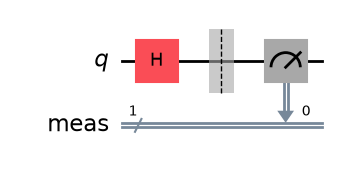

In [1]:
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler


def run(qc, shots):
    """回路を shots 回実行して、測定結果ごとの回数を返す。"""
    sampler = StatevectorSampler(seed=12345)  # 結果を再現できるように、乱数のシードを固定する
    result = sampler.run([qc], shots=shots).result()[0]
    return dict(sorted(result.data.meas.get_counts().items()))


qc_h = QuantumCircuit(1)
qc_h.h(0)
qc_h.measure_all()
qc_h.draw("mpl")

In [2]:
for shots in (100, 1000):
    print(f"{shots:>4}回: {run(qc_h, shots)}")

 100回: {'0': 62, '1': 38}
1000回: {'0': 526, '1': 474}


結果は 0 か 1 のどちらかで、100回では 62対38 と偏りますが、1000回では 526対474 とほぼ半々に近づきます。同じ回路を同じ条件で実行しても、1回ごとの結果は確率的に決まります。このため、量子回路の答えは、何回も実行した結果の分布として受け取ります。この実行の回数を**ショット数**と呼びます。

上の回路図の読み方を整理します。

- 横に伸びる1本の線が、1つの量子ビットを表します。
- 線の上の四角が、量子ゲートを表します。上の回路の H が、その1つです。回路図は左から右へ、ゲートを作用させる順に読みます。
- メーターの記号が、測定を表します。測定の結果は、下の `meas` の線に記録されます。

H ゲートは、測定すると 0 と 1 が半々の確率で得られる状態をつくります。この状態は、0 と 1 の**重ね合わせ**と呼ばれます。

## 干渉

0 と 1 が半々になる回路に、H ゲートをもう1回かけると、結果はどうなるでしょうか。

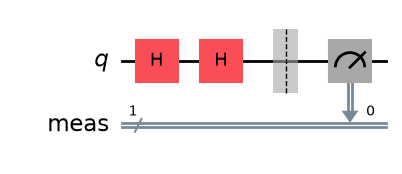

1000回: {'0': 1000}


In [3]:
qc_hh = QuantumCircuit(1)
qc_hh.h(0)
qc_hh.h(0)
qc_hh.measure_all()
display(qc_hh.draw("mpl"))
print(f"1000回: {run(qc_hh, 1000)}")

結果は、1000回すべてが 0 でした。H ゲートを1回かけると半々になるのに、もう1回かけると半々にならず、0 に戻ります。

古典のコインでは、こうはなりません。表と裏が半々のコインをもう1回投げても、結果は半々のままです。H ゲートの2回目は、「半々の確率で 0 か 1」という状態に、もう一度ランダムさを足す操作ではありません。1回目の H ゲートが作った重ね合わせの 0 の成分と 1 の成分が、2回目の H ゲートで互いに強め合ったり打ち消し合ったりして、0 だけが残ります。このように、重ね合わせの成分どうしが強め合ったり打ち消し合ったりして、測定で得られる確率が変わることを**干渉**と呼びます。

量子アルゴリズムは、この干渉を使います。正解が出る確率を強め、不正解が出る確率を打ち消すようにゲートを並べると、答えが分布の中で目立つようになります。第3章で扱う Grover の探索は、この考え方を使っています。

## もつれ

量子ビットが2つになると、結果は 00、01、10、11 の4通りになります。Qiskit では、右の数字が回路図の上の線(`q0`、1つ目の量子ビット)、左の数字が下の線(`q1`、2つ目の量子ビット)の結果です。

まず、2つの量子ビットのそれぞれに、独立に H ゲートをかけた回路を実行します。

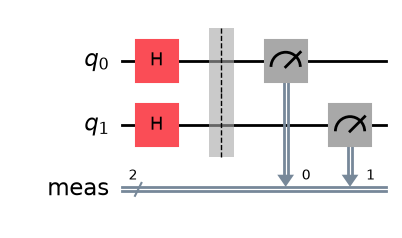

1000回: {'00': 247, '01': 279, '10': 251, '11': 223}


In [4]:
qc_indep = QuantumCircuit(2)
qc_indep.h(0)
qc_indep.h(1)
qc_indep.measure_all()
display(qc_indep.draw("mpl"))
print(f"1000回: {run(qc_indep, 1000)}")

4通りがほぼ25%ずつ出ました。2つの量子ビットの結果は、互いに無関係に決まっています。

次に、1つ目の量子ビットに H ゲートをかけたあと、**CNOT ゲート**を加えた回路を実行します。CNOT ゲートは、2つの量子ビットにまたがるゲートです。

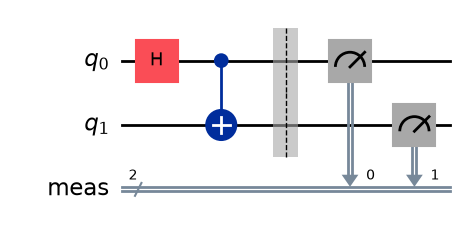

1000回: {'00': 526, '11': 474}


In [5]:
qc_bell = QuantumCircuit(2)
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure_all()
display(qc_bell.draw("mpl"))
print(f"1000回: {run(qc_bell, 1000)}")

In [6]:
def marginal(counts, position):
    """2量子ビットの測定結果から、position 番目のビットだけを見たときの 0 と 1 の回数を返す。"""
    totals = {"0": 0, "1": 0}
    for bits, count in counts.items():
        totals[bits[position]] += count
    return totals


for name, qc in (("独立に H", qc_indep), ("H と CNOT", qc_bell)):
    counts = run(qc, 1000)
    # Qiskit の測定結果の文字列は右端が 0 番目の量子ビット
    print(f"{name}: 1つ目の量子ビット {marginal(counts, 1)}, 2つ目の量子ビット {marginal(counts, 0)}")

独立に H: 1つ目の量子ビット {'0': 498, '1': 502}, 2つ目の量子ビット {'0': 526, '1': 474}
H と CNOT: 1つ目の量子ビット {'0': 526, '1': 474}, 2つ目の量子ビット {'0': 526, '1': 474}


In [7]:
for name, qc in (("独立に H", qc_indep), ("H と CNOT", qc_bell)):
    body = qc.remove_final_measurements(inplace=False)  # 測定を除いて数える
    print(f"{name}: ゲート {dict(body.count_ops())}, 2量子ビットゲート {body.num_nonlocal_gates()} 個, 深さ {body.depth()}")

独立に H: ゲート {'h': 2}, 2量子ビットゲート 0 個, 深さ 1
H と CNOT: ゲート {'h': 1, 'cx': 1}, 2量子ビットゲート 1 個, 深さ 2


結果は 00 と 11 だけで、約半々でした。01 と 10 は1回も出ていません。この1000回では、2つの量子ビットの結果は毎回一致しました。

ここで、量子ビットを1つずつ単独で見てみます。独立に H をかけた回路でも、H と CNOT の回路でも、どちらの量子ビットも 0 と 1 がほぼ半々です。つまり、1つずつ見る限り、2つの回路に違いはありません。違いが現れるのは、2つの結果を組にして見たときだけです。独立に H をかけた回路では4通りが出るのに対し、H と CNOT の回路では2通りしか出ません。

![2つの回路の測定結果。1つずつ見るとどちらも約50%で同じだが、出力の組み合わせは、独立に H をかけた回路は4通り、H と CNOT の回路は2通り](./resources/ch02-marginal-vs-joint.svg)

図の表の外側の数値が、量子ビットを1つずつ単独で見た割合です。表の中の数値が、2つの結果を組にして見た割合です。

このように、各量子ビットを別々に見ただけでは説明できない結果の関係を持つ状態を、**もつれ**た状態と呼びます。上の回路が作る状態は、**Bell 状態**と呼ばれます。CNOT のように2つの量子ビットにまたがるゲートを**2量子ビットゲート**、H のように1つの量子ビットだけに作用するゲートを**1量子ビットゲート**と呼びます。この章で確かめたのは、H を独立にかけた回路ではもつれが現れず、CNOT を加えると現れる、という点です。一般に、1量子ビットゲートだけでは、もつれを作れないことが知られています。

最後に、2つの回路のゲートの数と**深さ**を数えます。深さは、ゲートを並べたときに、前のゲートの完了を待つ段が何段あるかを表す数で、回路図の横の長さに当たります。独立に H をかけた回路は、2つの H を同時に実行できるので、深さは1です。H と CNOT の回路は、CNOT が H の完了を待つので、深さは2です。ゲートの数はどちらも2個で同じですが、深さは違います。

![独立に H をかけた回路は2つのゲートが1段に並び、H と CNOT の回路は2段に並ぶ](./resources/ch02-circuit-depth.svg)

ゲートの数と深さは、回路の大きさを比べる指標です。ゲートの数は回路に含まれる操作の総量を、深さは回路が横に何段続くかを表します。2つの回路は、ゲートの数が同じでも、深さで区別できます。2量子ビットゲートは、種類を分けて別に数えます(上の出力の「2量子ビットゲート」)。第3章以降では、回路どうしを比べるときに、この2量子ビットゲートの数と深さを使います。

## 実行環境

In [8]:
import ast
import platform
from importlib.metadata import packages_distributions, version

# このノートブックが import している Qiskit 系のパッケージだけを表示する
used = set()
for source in In:
    try:
        nodes = ast.walk(ast.parse(source))
    except SyntaxError:  # ! や % で始まるセルは読み飛ばす
        continue
    for node in nodes:
        if isinstance(node, ast.Import):
            tops = [a.name.split(".")[0] for a in node.names]
        elif isinstance(node, ast.ImportFrom) and node.level == 0:
            tops = [node.module.split(".")[0]]
        else:
            continue
        for top in tops:
            if top.startswith("qiskit"):
                used.update(packages_distributions().get(top, []))

print(f"{'python':<24} {'.'.join(platform.python_version().split('.')[:2])}")
for name in sorted(used):
    print(f"{name:<24} {version(name)}")

python                   3.12
qiskit                   2.4.2
